<a href="https://colab.research.google.com/github/keyvanmahmoudi/Deep_Learning_Course/blob/main/sessions/Session12_seq2seq_and_attention.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# جلسهٔ ۱۲: مدل‌های Sequence-to-Sequence و سازوکار Attention

### اهداف این جلسه

- درک معماری Encoder–Decoder برای تبدیل یک دنباله به دنباله‌ای با طول متفاوت
- پیاده‌سازی Seq2Seq با GRU، آموزش با Teacher Forcing و رمزگشایی حریصانه (Greedy Decoding)
- شناخت گلوگاه بردار زمینه (Context Vector) در Seq2Seq کلاسیک
- پیاده‌سازی Attention افزایشی (Bahdanau) و مقایسه با مدل بدون Attention
- تفسیر مدل با نمایش نقشه وزن‌های Attention

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۱. مسئله Sequence-to-Sequence

در ترجمه ماشینی، خلاصه‌سازی، پاسخ به پرسش و سیستم‌های گفت‌وگو، هم ورودی و هم خروجی دنباله‌اند و **طولشان می‌تواند متفاوت باشد**. «I love you» سه کلمه است و «دوستت دارم» دو کلمه.

معماری **Encoder–Decoder** (Sutskever et al., 2014; Cho et al., 2014) دو RNN دارد:

- **Encoder** کل دنباله ورودی را می‌خواند و آن را در حالت پنهان آخرش خلاصه می‌کند: **بردار زمینه (Context Vector)**.
- **Decoder** با شروع از بردار زمینه، دنباله خروجی را **Token به Token** تولید می‌کند؛ هر Token تولیدشده ورودی گام بعد است، تا زمانی که Token ویژه پایان (`<eos>`) تولید شود.

### مسئله این جلسه: تبدیل تاریخ

برای اینکه آموزش روی CPU هم در چند دقیقه انجام شود و نتایج کاملاً قابل تفسیر باشند، یک مسئله «ترجمه» کوچک می‌سازیم: تبدیل تاریخ‌هایی که انسان‌ها به شکل‌های مختلف می‌نویسند به قالب استاندارد ISO:

| ورودی | خروجی |
|---|---|
| `saturday, march 3, 2021` | `2021-03-03` |
| `3 mar 2021` | `2021-03-03` |
| `17.11.1998` | `1998-11-17` |

مدل باید یاد بگیرد کدام بخش ورودی روز، ماه یا سال است، نام ماه‌ها را به عدد تبدیل کند و ترتیب را عوض کند؛ یعنی دقیقاً چالش‌های ترجمه در مقیاس کوچک.

</div>

In [1]:
import random
import datetime as dt
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import Dataset, DataLoader

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)
random.seed(0)
torch.manual_seed(0)

device: cpu


In [2]:
FORMATS = [
    lambda d: d.strftime('%B %d, %Y'),               # march 03, 2021
    lambda d: f'{d.day} {d.strftime("%B")} {d.year}',  # 3 march 2021
    lambda d: f'{d.day} {d.strftime("%b")} {d.year}',  # 3 mar 2021
    lambda d: d.strftime('%A, %B %d, %Y'),           # wednesday, march 03, 2021
    lambda d: f'{d.strftime("%a")} {d.day} {d.strftime("%b")} {d.year}',
    lambda d: d.strftime('%d.%m.%Y'),                # 03.03.2021
    lambda d: d.strftime('%Y/%m/%d'),                # 2021/03/03
    lambda d: f'{d.strftime("%B")} {d.day} {d.year}',  # march 3 2021
    lambda d: f'the {d.day} of {d.strftime("%B")}, {d.year}',
]


def random_date():
    start = dt.date(1950, 1, 1).toordinal()
    return dt.date.fromordinal(random.randint(start, dt.date(2050, 12, 31).toordinal()))


def make_pair():
    d = random_date()
    return random.choice(FORMATS)(d).lower(), d.isoformat()


pairs = [make_pair() for _ in range(30_000)]
for src, tgt in pairs[:8]:
    print(f'{src:32s} -> {tgt}')

2019/02/15                       -> 2019-02-15
sun 7 apr 1957                   -> 1957-04-07
september 26 2041                -> 2041-09-26
sun 28 aug 2022                  -> 2022-08-28
08.07.2035                       -> 2035-07-08
the 12 of march, 1989            -> 1989-03-12
sat 28 dec 1974                  -> 1974-12-28
28 january 1975                  -> 1975-01-28


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### واژگان در سطح کاراکتر

چون ورودی و خروجی کوتاه‌اند، مدل را در **سطح کاراکتر** می‌سازیم. سه Token ویژه داریم: `<pad>`، `<sos>` (شروع دنباله خروجی) و `<eos>` (پایان دنباله).

</div>

In [3]:
PAD, SOS, EOS = 0, 1, 2
src_chars = sorted({c for s, _ in pairs for c in s})
tgt_chars = sorted({c for _, t in pairs for c in t})
src_itos = ['<pad>', '<sos>', '<eos>'] + src_chars
tgt_itos = ['<pad>', '<sos>', '<eos>'] + tgt_chars
src_stoi = {c: i for i, c in enumerate(src_itos)}
tgt_stoi = {c: i for i, c in enumerate(tgt_itos)}
print('source vocabulary:', len(src_itos), '| target vocabulary:', len(tgt_itos), tgt_chars)


class DateDataset(Dataset):
    def __init__(self, pairs):
        self.src = [torch.tensor([src_stoi[c] for c in s] + [EOS]) for s, _ in pairs]
        self.tgt = [torch.tensor([SOS] + [tgt_stoi[c] for c in t] + [EOS]) for _, t in pairs]

    def __len__(self):
        return len(self.src)

    def __getitem__(self, i):
        return self.src[i], self.tgt[i]


def collate(batch):
    src, tgt = zip(*batch)
    return pad_sequence(src, batch_first=True, padding_value=PAD), pad_sequence(tgt, batch_first=True, padding_value=PAD)


train_pairs, val_pairs, test_pairs = pairs[:24_000], pairs[24_000:27_000], pairs[27_000:]
train_loader = DataLoader(DateDataset(train_pairs), batch_size=128, shuffle=True, collate_fn=collate)
val_loader = DataLoader(DateDataset(val_pairs), batch_size=512, collate_fn=collate)
S, T = next(iter(train_loader))
print('source batch:', tuple(S.shape), '| target batch:', tuple(T.shape))

source vocabulary: 39 | target vocabulary: 14 ['-', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


source batch: (128, 28) | target batch: (128, 12)


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۲. Seq2Seq کلاسیک (بدون Attention)

**Encoder:** Embedding و یک GRU دوطرفه. حالت نهایی دو جهت را با یک لایه Linear به حالت اولیه Decoder تبدیل می‌کنیم.

**Decoder:** در هر گام، Embedding آخرین Token و حالت قبلی را می‌گیرد و توزیع احتمال Token بعدی را می‌دهد.

### Teacher Forcing

در آموزش، به‌جای اینکه پیش‌بینی خود Decoder (که در ابتدای آموزش تقریباً همیشه غلط است) را ورودی گام بعد کنیم، **Token درست** را از خروجی هدف به آن می‌دهیم. این روش **Teacher Forcing** نام دارد و آموزش را بسیار سریع‌تر و پایدارتر می‌کند. عیب آن: در زمان استفاده، مدل باید روی پیش‌بینی‌های خودش کار کند و ممکن است خطاها انباشته شوند (**Exposure Bias**).

با Teacher Forcing، ورودی Decoder دنباله هدف بدون آخرین Token (`<sos> 2 0 2 1 ...`) و خروجی مورد انتظار همان دنباله بدون اولین Token (`2 0 2 1 ... <eos>`) است؛ یعنی یک جابه‌جایی یک‌گامی.

</div>

In [4]:
class Encoder(nn.Module):
    def __init__(self, vocab, emb=64, hidden=128):
        super().__init__()
        self.embedding = nn.Embedding(vocab, emb, padding_idx=PAD)
        self.rnn = nn.GRU(emb, hidden, batch_first=True, bidirectional=True)
        self.bridge = nn.Linear(2 * hidden, hidden)              # map both directions to the decoder state

    def forward(self, src):
        outputs, h = self.rnn(self.embedding(src))               # outputs: (B, S, 2H), h: (2, B, H)
        h0 = torch.tanh(self.bridge(torch.cat([h[0], h[1]], dim=1))).unsqueeze(0)
        return outputs, h0


class Decoder(nn.Module):
    def __init__(self, vocab, emb=64, hidden=128):
        super().__init__()
        self.embedding = nn.Embedding(vocab, emb, padding_idx=PAD)
        self.rnn = nn.GRU(emb, hidden, batch_first=True)
        self.out = nn.Linear(hidden, vocab)

    def forward(self, tgt_in, h, enc_outputs=None, src_mask=None):
        out, h = self.rnn(self.embedding(tgt_in), h)             # all steps at once (teacher forcing)
        return self.out(out), h, None


class Seq2Seq(nn.Module):
    def __init__(self, encoder, decoder):
        super().__init__()
        self.encoder, self.decoder = encoder, decoder

    def forward(self, src, tgt_in):
        enc_out, h = self.encoder(src)
        logits, _, _ = self.decoder(tgt_in, h, enc_out, src != PAD)
        return logits

    @torch.no_grad()
    def greedy_decode(self, src, max_len=12):
        """Generate one token at a time, feeding back the model's own predictions."""
        enc_out, h = self.encoder(src)
        token = torch.full((src.shape[0], 1), SOS, dtype=torch.long, device=src.device)
        outputs, attentions = [], []
        for _ in range(max_len):
            logits, h, attn = self.decoder(token, h, enc_out, src != PAD)
            token = logits.argmax(-1)
            outputs.append(token)
            if attn is not None:
                attentions.append(attn)
        attn = torch.cat(attentions, dim=1) if attentions else None
        return torch.cat(outputs, dim=1), attn

In [5]:
def to_text(ids):
    chars = []
    for i in ids:
        if i == EOS:
            break
        chars.append(tgt_itos[i])
    return ''.join(chars)


def exact_match(model, pairs, batch_size=512):
    model.eval()
    loader = DataLoader(DateDataset(pairs), batch_size=batch_size, collate_fn=collate)
    correct, i = 0, 0
    for src, _ in loader:
        pred, _ = model.greedy_decode(src.to(device))
        for row in pred.tolist():
            correct += to_text(row) == pairs[i][1]
            i += 1
    return correct / len(pairs)


def train_seq2seq(model, epochs=10, lr=2e-3):
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    history = []
    for epoch in range(1, epochs + 1):
        model.train()
        total = 0
        for src, tgt in train_loader:
            src, tgt = src.to(device), tgt.to(device)
            tgt_in, tgt_out = tgt[:, :-1], tgt[:, 1:]            # shift by one step
            logits = model(src, tgt_in)
            loss = F.cross_entropy(logits.reshape(-1, logits.shape[-1]), tgt_out.reshape(-1), ignore_index=PAD)
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            total += loss.item()
        acc = exact_match(model, val_pairs)
        history.append(acc)
        print(f'epoch {epoch:2d} | train loss {total / len(train_loader):.4f} | val exact match {acc:.4f}')
    return history


EPOCHS = 10
torch.manual_seed(0)
plain = Seq2Seq(Encoder(len(src_itos)), Decoder(len(tgt_itos)))
hist_plain = train_seq2seq(plain, EPOCHS)

epoch  1 | train loss 1.0378 | val exact match 0.0003


epoch  2 | train loss 0.6424 | val exact match 0.0117


epoch  3 | train loss 0.4116 | val exact match 0.0867


epoch  4 | train loss 0.2438 | val exact match 0.4253


epoch  5 | train loss 0.1193 | val exact match 0.6507


epoch  6 | train loss 0.0554 | val exact match 0.9437


epoch  7 | train loss 0.0270 | val exact match 0.9230


epoch  8 | train loss 0.0109 | val exact match 0.9993


epoch  9 | train loss 0.0031 | val exact match 0.9997


epoch 10 | train loss 0.0019 | val exact match 0.9997


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

در محاسبه Loss از `ignore_index=PAD` استفاده کردیم تا مکان‌های Padding در خطا حساب نشوند. معیار ارزیابی **تطابق کامل (Exact Match)** است: خروجی فقط وقتی درست است که همه ۱۰ کاراکتر درست باشند.

## ۳. گلوگاه بردار زمینه

در Seq2Seq کلاسیک، **کل** اطلاعات ورودی باید در **یک** بردار با اندازه ثابت فشرده شود. برای جمله‌های طولانی این یک گلوگاه جدی است: Bahdanau و همکاران نشان دادند کیفیت ترجمه مدل‌های Seq2Seq کلاسیک با افزایش طول جمله به‌شدت افت می‌کند.

ایده **Attention** (Bahdanau et al., 2015): Decoder در هر گام، به‌جای اتکا به یک بردار ثابت، به **همه حالت‌های Encoder** نگاه کند و خودش تصمیم بگیرد در این لحظه روی کدام بخش ورودی «تمرکز» کند. مثلاً هنگام تولید ارقام ماه، روی کلمه «march» یا عدد ماه در ورودی.

## ۴. Attention افزایشی (Bahdanau)

در گام $t$ Decoder، با حالت پنهان قبلی $\mathbf{s}_{t-1}$ و حالت‌های Encoder $\mathbf{h}_1, \dots, \mathbf{h}_S$:

۱. **امتیاز (Score)** هر مکان ورودی:
$$e_{t,j} = \mathbf{v}^\top \tanh\left(W_s\,\mathbf{s}_{t-1} + W_h\,\mathbf{h}_j\right)$$

۲. **وزن‌های Attention** با Softmax (مکان‌های Padding با مقدار $-\infty$ حذف می‌شوند):
$$\alpha_{t,j} = \frac{\exp(e_{t,j})}{\sum_k \exp(e_{t,k})}$$

۳. **بردار زمینه** مخصوص همین گام، میانگین وزن‌دار حالت‌های Encoder:
$$\mathbf{c}_t = \sum_j \alpha_{t,j}\,\mathbf{h}_j$$

۴. ورودی RNN در این گام، الحاق Embedding Token قبلی و $\mathbf{c}_t$ است.

چون Decoder با Attention در هر گام به حالت جدید وابسته است، باید آن را **گام‌به‌گام** در یک حلقه اجرا کنیم (حتی با Teacher Forcing).

</div>

In [6]:
class AdditiveAttention(nn.Module):
    def __init__(self, dec_hidden, enc_hidden, attn_dim=128):
        super().__init__()
        self.W_s = nn.Linear(dec_hidden, attn_dim, bias=False)
        self.W_h = nn.Linear(enc_hidden, attn_dim, bias=False)
        self.v = nn.Linear(attn_dim, 1, bias=False)

    def forward(self, s, enc_outputs, mask):
        """s: (B, H_dec), enc_outputs: (B, S, H_enc), mask: (B, S) -> context (B, H_enc), weights (B, S)"""
        scores = self.v(torch.tanh(self.W_s(s).unsqueeze(1) + self.W_h(enc_outputs))).squeeze(-1)
        scores = scores.masked_fill(~mask, float('-inf'))       # never attend to padding
        weights = torch.softmax(scores, dim=1)
        context = torch.bmm(weights.unsqueeze(1), enc_outputs).squeeze(1)
        return context, weights


class AttnDecoder(nn.Module):
    def __init__(self, vocab, emb=64, hidden=128, enc_hidden=256):
        super().__init__()
        self.embedding = nn.Embedding(vocab, emb, padding_idx=PAD)
        self.attention = AdditiveAttention(hidden, enc_hidden)
        self.rnn = nn.GRU(emb + enc_hidden, hidden, batch_first=True)
        self.out = nn.Linear(hidden + enc_hidden, vocab)

    def forward(self, tgt_in, h, enc_outputs, src_mask):
        emb = self.embedding(tgt_in)
        logits, weights = [], []
        for t in range(tgt_in.shape[1]):                          # step by step: attention depends on the state
            context, w = self.attention(h[-1], enc_outputs, src_mask)
            rnn_in = torch.cat([emb[:, t], context], dim=1).unsqueeze(1)
            out, h = self.rnn(rnn_in, h)
            logits.append(self.out(torch.cat([out.squeeze(1), context], dim=1)))
            weights.append(w)
        return torch.stack(logits, dim=1), h, torch.stack(weights, dim=1)


torch.manual_seed(0)
attn_model = Seq2Seq(Encoder(len(src_itos)), AttnDecoder(len(tgt_itos)))
hist_attn = train_seq2seq(attn_model, EPOCHS)

epoch  1 | train loss 0.3145 | val exact match 1.0000


epoch  2 | train loss 0.0006 | val exact match 1.0000


epoch  3 | train loss 0.0002 | val exact match 1.0000


epoch  4 | train loss 0.0001 | val exact match 1.0000


epoch  5 | train loss 0.0001 | val exact match 1.0000


epoch  6 | train loss 0.0001 | val exact match 1.0000


epoch  7 | train loss 0.0000 | val exact match 1.0000


epoch  8 | train loss 0.0000 | val exact match 1.0000


epoch  9 | train loss 0.0000 | val exact match 1.0000


epoch 10 | train loss 0.0000 | val exact match 1.0000


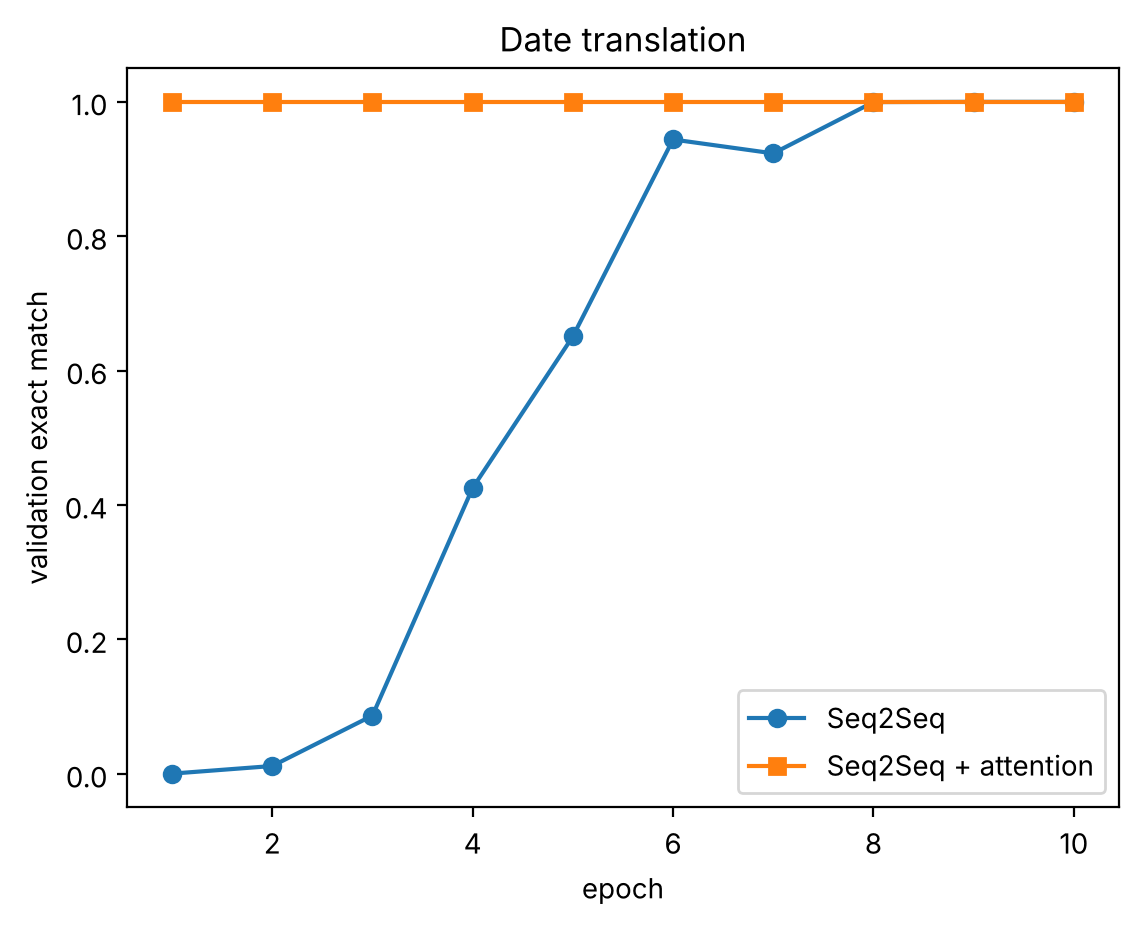

test exact match | without attention: 0.9993 | with attention: 1.0000


In [7]:
plt.plot(range(1, EPOCHS + 1), hist_plain, 'o-', label='Seq2Seq')
plt.plot(range(1, EPOCHS + 1), hist_attn, 's-', label='Seq2Seq + attention')
plt.xlabel('epoch'); plt.ylabel('validation exact match'); plt.legend(); plt.title('Date translation')
plt.show()

print(f'test exact match | without attention: {exact_match(plain, test_pairs):.4f} | with attention: {exact_match(attn_model, test_pairs):.4f}')

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

هر دو مدل در نهایت این مسئله نسبتاً ساده را تقریباً کامل حل می‌کنند، اما مدل با Attention از همان Epoch اول به دقت کامل می‌رسد، در حالی که مدل بدون Attention چندین Epoch لازم دارد. در مسائل واقعی با دنباله‌های طولانی (مثل ترجمه جمله‌های بلند) این تفاوت در دقت نهایی هم دیده می‌شود. مهم‌تر از سرعت، Attention مدل را **قابل تفسیر** می‌کند.

## ۵. نمایش نقشه Attention

برای هر کاراکتر خروجی (سطرها)، وزن Attention روی کاراکترهای ورودی (ستون‌ها) را رسم می‌کنیم:

</div>

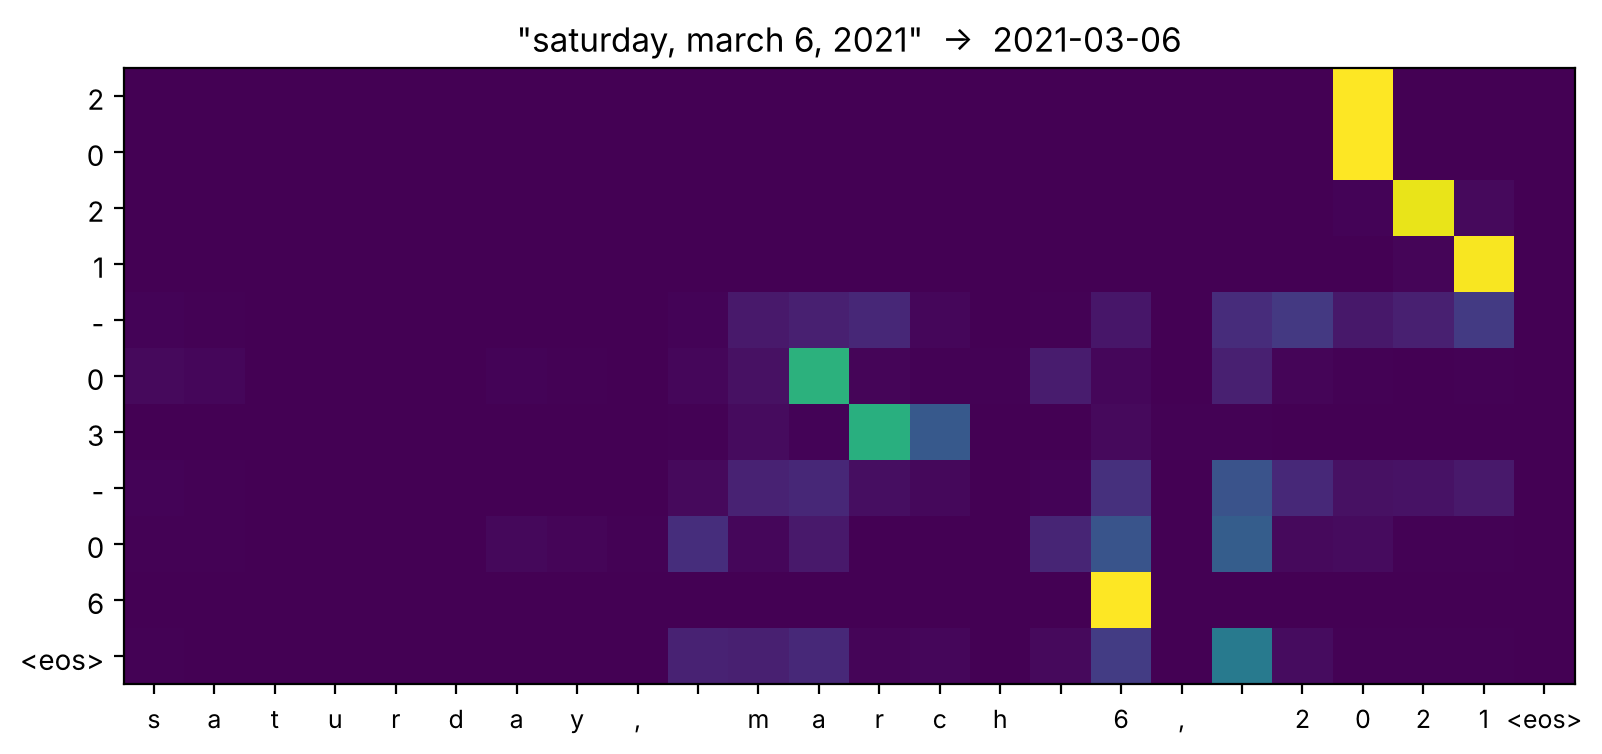

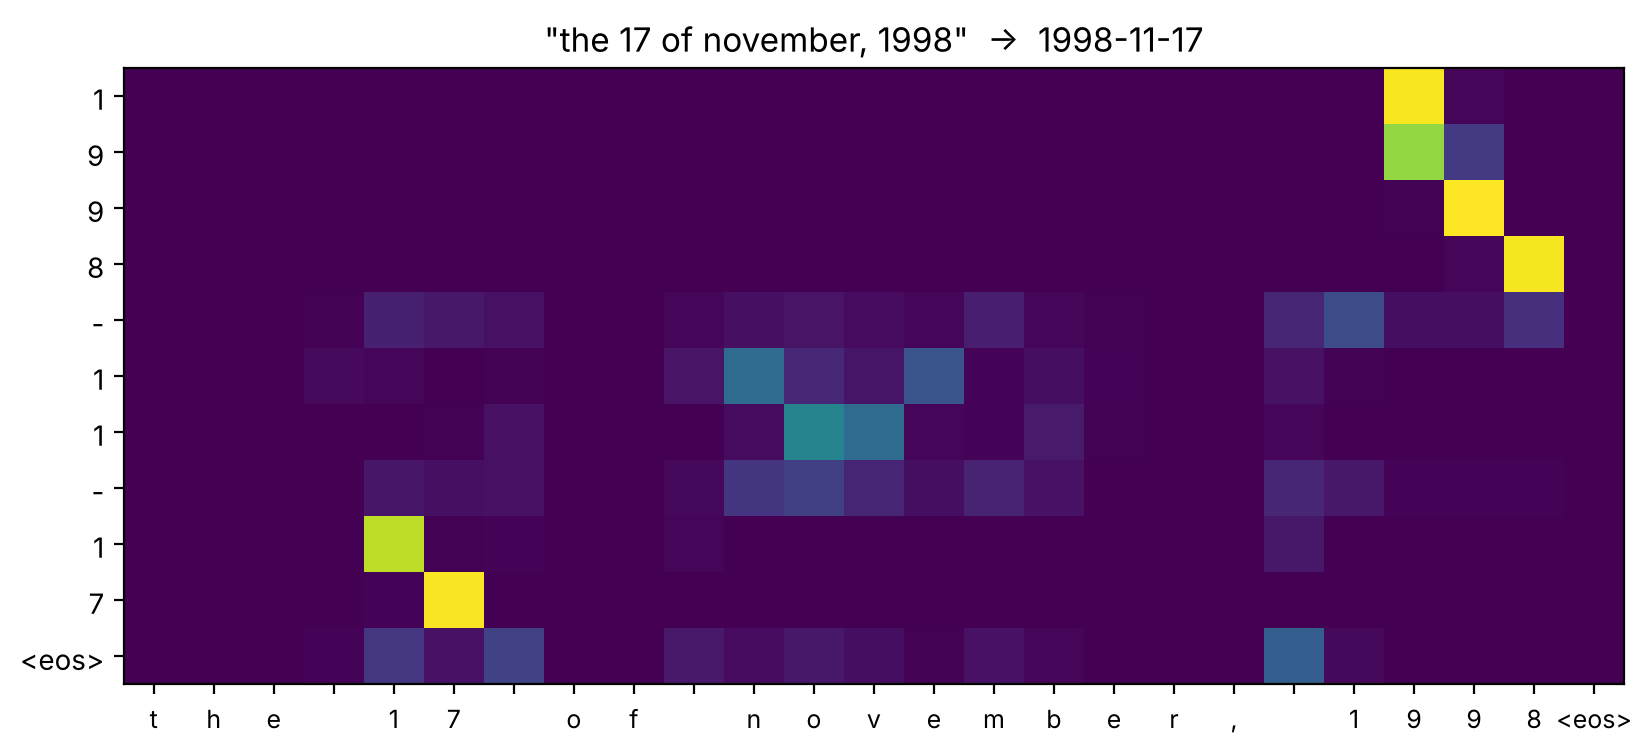

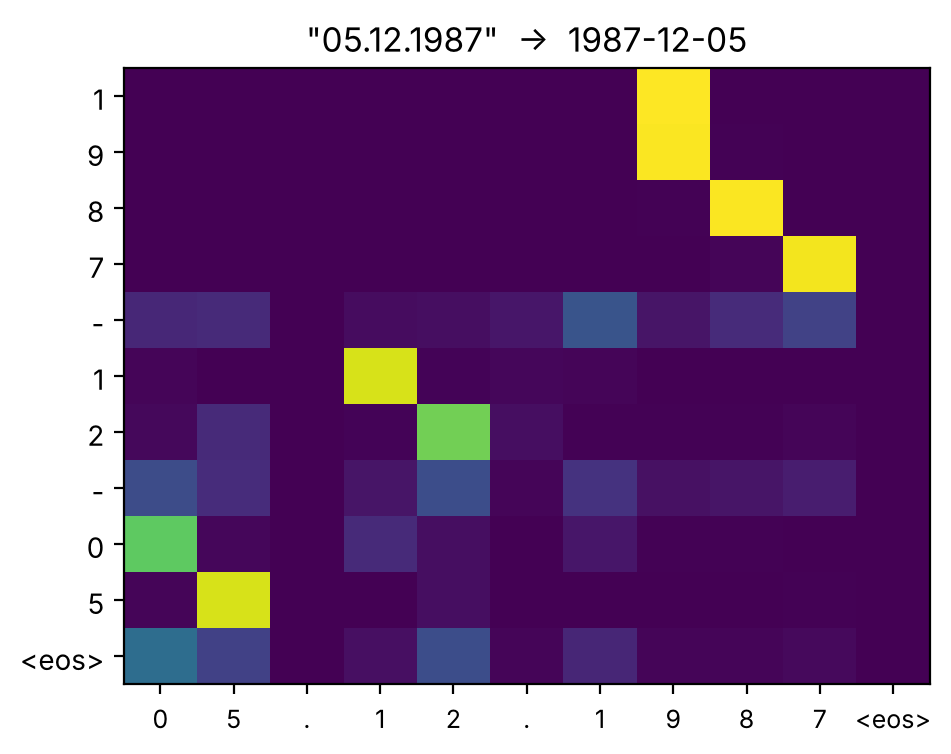

In [8]:
def plot_attention(model, text):
    src = torch.tensor([[src_stoi[c] for c in text] + [EOS]]).to(device)
    model.eval()
    pred, attn = model.greedy_decode(src)
    out = to_text(pred[0].tolist())
    attn = attn[0, :len(out) + 1, :].cpu().numpy()             # rows: output chars (+ <eos>), cols: input chars (+ <eos>)
    fig, ax = plt.subplots(figsize=(0.32 * len(text) + 2, 4))
    ax.imshow(attn, cmap='viridis', aspect='auto')
    ax.set_xticks(range(len(text) + 1)); ax.set_xticklabels(list(text) + ['<eos>'], fontsize=9)
    ax.set_yticks(range(len(out) + 1)); ax.set_yticklabels(list(out) + ['<eos>'])
    ax.set_title(f'"{text}"  ->  {out}')
    plt.show()


for text in ['saturday, march 6, 2021', 'the 17 of november, 1998', '05.12.1987']:
    plot_attention(attn_model, text)

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

مدل هنگام تولید ارقام سال به ارقام سال در ورودی نگاه می‌کند (گاهی یک کاراکتر جلوتر، چون حالت Encoder دوطرفه اطلاعات همسایه‌ها را هم دارد)، هنگام تولید ماه به حروف متمایزکننده نام ماه و هنگام تولید روز به عدد روز. این **هم‌ترازی (Alignment)** را هیچ‌کس به مدل نگفته؛ خودش از روی داده یاد گرفته است.

### امتحان روی ورودی‌های دلخواه

</div>

In [9]:
def translate(model, text):
    src = torch.tensor([[src_stoi.get(c, PAD) for c in text.lower()] + [EOS]]).to(device)
    return to_text(model.greedy_decode(src)[0][0].tolist())


for text in ['march 21 2025', 'tue 1 jan 2030', '2001/09/11', 'the 4 of july, 1976']:
    print(f'{text:25s} -> plain: {translate(plain, text):12s} | attention: {translate(attn_model, text)}')

march 21 2025             -> plain: 2025-03-21   | attention: 2025-03-21
tue 1 jan 2030            -> plain: 2030-01-01   | attention: 2030-01-01
2001/09/11                -> plain: 2001-09-11   | attention: 2001-09-11
the 4 of july, 1976       -> plain: 1976-07-04   | attention: 1976-07-04


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۶. فراتر از Greedy Decoding

رمزگشایی حریصانه در هر گام فقط محتمل‌ترین Token را انتخاب می‌کند و ممکن است دنباله کلی بهینه را از دست بدهد. **Beam Search** در هر گام $k$ دنباله جزئی محتمل‌تر را نگه می‌دارد و در ترجمه ماشینی کیفیت را بهتر می‌کند. در مدل‌های زبانی بزرگ امروزی از روش‌های **نمونه‌برداری (Sampling)** مثل Temperature و Top-p هم استفاده می‌شود (جلسه ۱۳).

## ۷. از Attention به Transformer

Attention مشکل گلوگاه را حل کرد، اما مدل هنوز RNN است: پردازش **ترتیبی** است و روی GPU قابل موازی‌سازی کامل نیست. ایده انقلابی مقاله **«Attention Is All You Need»** (Vaswani et al., 2017): RNN را کاملاً حذف کنیم و فقط از Attention استفاده کنیم؛ حتی برای ارتباط کلمات **یک** دنباله با هم (**Self-Attention**). این معماری، **Transformer**، موضوع جلسه بعد و پایه همه مدل‌های زبانی بزرگ امروزی است.

## جمع‌بندی

- Encoder–Decoder دنباله‌ای را به دنباله‌ای با طول متفاوت تبدیل می‌کند؛ Decoder Token به Token تولید می‌کند تا به `<eos>` برسد.
- **Teacher Forcing:** در آموزش، Token درست (نه پیش‌بینی مدل) ورودی گام بعد است؛ ورودی و خروجی Decoder یک گام جابه‌جا هستند.
- `ignore_index=PAD` در Loss و Masking در Attention، Padding را از محاسبات حذف می‌کنند.
- بردار زمینه ثابت یک گلوگاه است؛ **Attention** در هر گام میانگین وزن‌داری از همه حالت‌های Encoder می‌سازد.
- وزن‌های Attention هم‌ترازی بین ورودی و خروجی را نشان می‌دهند و مدل را تفسیرپذیر می‌کنند.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## تمرین‌ها

هر تمرین را در سلول کد زیر آن حل کنید. پاسخ پیشنهادی در پوشهٔ `solutions` آمده است.

۱. **Attention ضرب نقطه‌ای (Luong / Dot-product)** را پیاده کنید: $e_{t,j} = \mathbf{s}_{t-1}^\top W \mathbf{h}_j$. نتیجه و سرعت را با Attention افزایشی مقایسه کنید.

۲. چند قالب تاریخ جدید (مثلاً `3rd of march 2021` یا تاریخ با ماه‌های فارسی) به `FORMATS` اضافه کنید و ببینید مدل آموزش‌دیده چطور با قالب‌های ناآشنا برخورد می‌کند. سپس با داده جدید دوباره آموزش دهید.

۳. **Scheduled Sampling** را پیاده کنید: در آموزش با احتمال $p$ (که به‌تدریج زیاد می‌شود) به‌جای Token درست، پیش‌بینی خود مدل را ورودی گام بعد کنید.

۴. Beam Search با اندازه پرتو ۳ را برای `attn_model` پیاده کنید.

۵. همین کد را برای یک مسئله «ترجمه» دیگر تغییر دهید: تبدیل اعداد نوشته‌شده با حروف انگلیسی به رقم (مثلاً `two hundred and five` به `205`).

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۱.** **Attention ضرب نقطه‌ای (Luong / Dot-product)** را پیاده کنید: $e_{t,j} = \mathbf{s}_{t-1}^\top W \mathbf{h}_j$. نتیجه و سرعت را با Attention افزایشی مقایسه کنید.

</div>

In [10]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۲.** چند قالب تاریخ جدید (مثلاً `3rd of march 2021` یا تاریخ با ماه‌های فارسی) به `FORMATS` اضافه کنید و ببینید مدل آموزش‌دیده چطور با قالب‌های ناآشنا برخورد می‌کند. سپس با داده جدید دوباره آموزش دهید.

</div>

In [11]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۳.** **Scheduled Sampling** را پیاده کنید: در آموزش با احتمال $p$ (که به‌تدریج زیاد می‌شود) به‌جای Token درست، پیش‌بینی خود مدل را ورودی گام بعد کنید.

</div>

In [12]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۴.** Beam Search با اندازه پرتو ۳ را برای `attn_model` پیاده کنید.

</div>

In [13]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۵.** همین کد را برای یک مسئله «ترجمه» دیگر تغییر دهید: تبدیل اعداد نوشته‌شده با حروف انگلیسی به رقم (مثلاً `two hundred and five` به `205`).

</div>

In [14]:
# پاسخ خود را اینجا بنویسید
